In [1]:

# Cell 1: Check the Google Colab environment

import os
import sys

print("Python version:", sys.version)
print("Waste Segregation AI project started!")

print("Working directory:", os.getcwd())
print("Project setup successful!")


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Waste Segregation AI project started!
Working directory: /content
Project setup successful!


In [2]:

# Cell 2: Install required libraries

!pip install -q ultralytics opencv-python matplotlib pandas

print("All required libraries installed successfully!")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 36.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 6.0 MB/s eta 0:00:00
All required libraries installed successfully!


In [4]:

import os

# Check the downloaded dataset folders
dataset_path = "/content"

print("Checking dataset folders...\n")

for root, dirs, files in os.walk(dataset_path):
    if any(folder in root.lower() for folder in ["train", "valid", "test"]):
        print("Folder:", root)
        print("Number of files:", len(files))


Checking dataset folders...



In [5]:

import os

print("Files and folders inside /content:\n")

for item in os.listdir("/content"):
    path = os.path.join("/content", item)

    if os.path.isdir(path):
        print("📁 Folder:", item)
    else:
        print("📄 File:", item)


Files and folders inside /content:

📁 Folder: .config
📁 Folder: sample_data


In [6]:

!pip install -q kagglehub

import kagglehub
import os

# Download the waste classification dataset
dataset_path = kagglehub.dataset_download(
    "asdasdasasdas/garbage-classification"
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)

print("\nFiles and folders:")
for item in os.listdir(dataset_path):
    print(item)


Using Colab cache for faster access to the 'garbage-classification' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/garbage-classification

Files and folders:
one-indexed-files-notrash_val.txt
one-indexed-files-notrash_train.txt
Garbage classification
garbage classification
zero-indexed-files.txt
one-indexed-files.txt
one-indexed-files-notrash_test.txt


In [7]:

import os

dataset_path = "/kaggle/input/garbage-classification"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    # Display only the first few folder levels
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        if level == 2:
            print("  " * (level + 1) +
                  f"Number of images/files: {len(files)}")


garbage-classification/
  Garbage classification/
    Garbage classification/
      Number of images/files: 0
  garbage classification/
    Garbage classification/
      Number of images/files: 0


In [8]:

import os

dataset_path = "/kaggle/input/garbage-classification"

for root, dirs, files in os.walk(dataset_path):
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    if image_files:
        print("Category folder:", root)
        print("Number of images:", len(image_files))
        print("-" * 40)

print("Dataset inspection completed!")


Category folder: /kaggle/input/garbage-classification/Garbage classification/Garbage classification/metal
Number of images: 410
----------------------------------------
Category folder: /kaggle/input/garbage-classification/Garbage classification/Garbage classification/glass
Number of images: 501
----------------------------------------
Category folder: /kaggle/input/garbage-classification/Garbage classification/Garbage classification/paper
Number of images: 594
----------------------------------------
Category folder: /kaggle/input/garbage-classification/Garbage classification/Garbage classification/trash
Number of images: 137
----------------------------------------
Category folder: /kaggle/input/garbage-classification/Garbage classification/Garbage classification/cardboard
Number of images: 403
----------------------------------------
Category folder: /kaggle/input/garbage-classification/Garbage classification/Garbage classification/plastic
Number of images: 482
---------------------

In [9]:

import os
import shutil
import random
from pathlib import Path

# Use one copy of the dataset
source_dir = Path(
    "/kaggle/input/garbage-classification/"
    "Garbage classification/Garbage classification"
)

output_dir = Path("/content/waste_dataset")

categories = [
    "cardboard", "glass", "metal",
    "paper", "plastic", "trash"
]

random.seed(42)

# Create train, validation, and test folders
for split in ["train", "val", "test"]:
    for category in categories:
        (output_dir / split / category).mkdir(
            parents=True, exist_ok=True
        )

# Split images: 80% train, 10% validation, 10% test
for category in categories:
    category_dir = source_dir / category

    images = [
        f for f in category_dir.iterdir()
        if f.is_file() and
        f.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
    ]

    random.shuffle(images)

    n = len(images)
    train_end = int(n * 0.8)
    val_end = int(n * 0.9)

    splits = {
        "train": images[:train_end],
        "val": images[train_end:val_end],
        "test": images[val_end:]
    }

    for split, files in splits.items():
        for file in files:
            shutil.copy2(
                file,
                output_dir / split / category / file.name
            )

    print(
        f"{category}: {len(splits['train'])} train, "
        f"{len(splits['val'])} validation, "
        f"{len(splits['test'])} test"
    )

print("\nDataset preparation completed!")
print("Dataset location:", output_dir)


cardboard: 322 train, 40 validation, 41 test
glass: 400 train, 50 validation, 51 test
metal: 328 train, 41 validation, 41 test
paper: 475 train, 59 validation, 60 test
plastic: 385 train, 48 validation, 49 test
trash: 109 train, 14 validation, 14 test

Dataset preparation completed!
Dataset location: /content/waste_dataset


In [10]:

from pathlib import Path

for split in ["train", "val", "test"]:
    total = sum(
        1 for f in (output_dir / split).rglob("*")
        if f.is_file()
    )
    print(f"{split}: {total} images")


train: 2019 images
val: 252 images
test: 256 images


In [11]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from pathlib import Path

# Dataset paths
train_dir = "/content/waste_dataset/train"
val_dir = "/content/waste_dataset/val"
test_dir = "/content/waste_dataset/test"

# Image settings
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# Load training images
train_ds = keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    seed=SEED
)

# Load validation images
val_ds = keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Load test images
test_ds = keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

print("\nWaste categories:", class_names)
print("Number of categories:", len(class_names))

# Improve data-loading performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("\nDatasets loaded successfully!")


Found 2019 files belonging to 6 classes.
Found 252 files belonging to 6 classes.
Found 256 files belonging to 6 classes.

Waste categories: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Number of categories: 6

Datasets loaded successfully!


In [12]:

from tensorflow import keras
from tensorflow.keras import layers

# Load pretrained MobileNetV2
base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# Build the waste classification model
inputs = keras.Input(shape=(224, 224, 3))

# Preprocess images for MobileNetV2
x = keras.applications.mobilenet_v2.preprocess_input(inputs)

# Extract image features
x = base_model(x, training=False)

# Convert features into a vector
x = layers.GlobalAveragePooling2D()(x)

# Add regularization
x = layers.Dropout(0.2)(x)

# Predict 6 waste categories
outputs = layers.Dense(6, activation="softmax")(x)

model = keras.Model(inputs, outputs)

# Configure training
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model structure
model.summary()

print("\nWaste classification model created successfully!")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


Waste classification model created successfully!


In [13]:

# Train the waste classification model

EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

print("\nModel training completed successfully!")
,""

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 111s 2s/step - accuracy: 0.5686 - loss: 1.1214 - val_accuracy: 0.7579 - val_loss: 0.7087
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 110s 2s/step - accuracy: 0.7831 - loss: 0.5999 - val_accuracy: 0.7698 - val_loss: 0.6163
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 139s 2s/step - accuracy: 0.8341 - loss: 0.4900 - val_accuracy: 0.8095 - val_loss: 0.5399
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 97s 2s/step - accuracy: 0.8514 - loss: 0.4301 - val_accuracy: 0.8214 - val_loss: 0.4982
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 144s 2s/step - accuracy: 0.8732 - loss: 0.3751 - val_accuracy: 0.8175 - val_loss: 0.4962
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 158s 2s/step - accuracy: 0.8856 - loss: 0.3369 - val_accuracy: 0.8373 - val_loss: 0.4879
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 125s 2s/step - accuracy: 0.8930 - loss: 0.3097 - val_accuracy: 0.8214 - val_loss: 0.4560
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 142s 2s/step - accuracy: 0.9074 - loss: 0.2808 - val_accuracy: 0.8294 - va

In [14]:

# Evaluate the model on unseen test images

test_loss, test_accuracy = model.evaluate(test_ds)

print("\n========== TEST RESULTS ==========")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print("==================================")


8/8 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.8477 - loss: 0.4395

========== TEST RESULTS ==========
Test Accuracy: 84.77%
Test Loss: 0.4395


In [15]:

# Save the trained model
model.save("/content/waste_segregation_model.keras")

print("Model saved successfully!")
print("File: /content/waste_segregation_model.keras")


Model saved successfully!
File: /content/waste_segregation_model.keras


Saving Screenshot 2026-10-18 121456.png to Screenshot 2026-10-18 121456.png


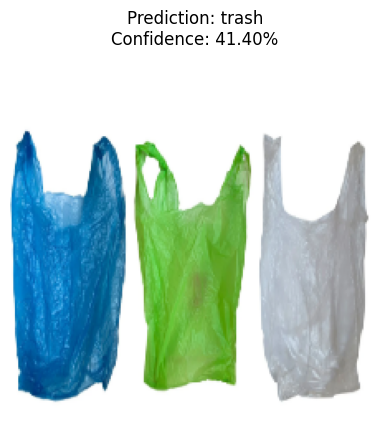

Predicted waste category: trash
Prediction confidence: 41.40%


In [16]:

from google.colab import files
from tensorflow import keras
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

# Upload an image from your computer
uploaded = files.upload()

# Load the trained model
model = keras.models.load_model(
    "/content/waste_segregation_model.keras"
)

# Waste categories in the same order as training
class_names = [
    "cardboard", "glass", "metal",
    "paper", "plastic", "trash"
]

# Process and predict the uploaded image
for filename in uploaded.keys():
    img = image.load_img(
        filename,
        target_size=(224, 224)
    )

    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    predictions = model.predict(img_array, verbose=0)[0]

    predicted_index = np.argmax(predictions)
    predicted_class = class_names[predicted_index]
    confidence = predictions[predicted_index] * 100

    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence:.2f}%"
    )
    plt.show()

    print("Predicted waste category:", predicted_class)
    print(f"Prediction confidence: {confidence:.2f}%")


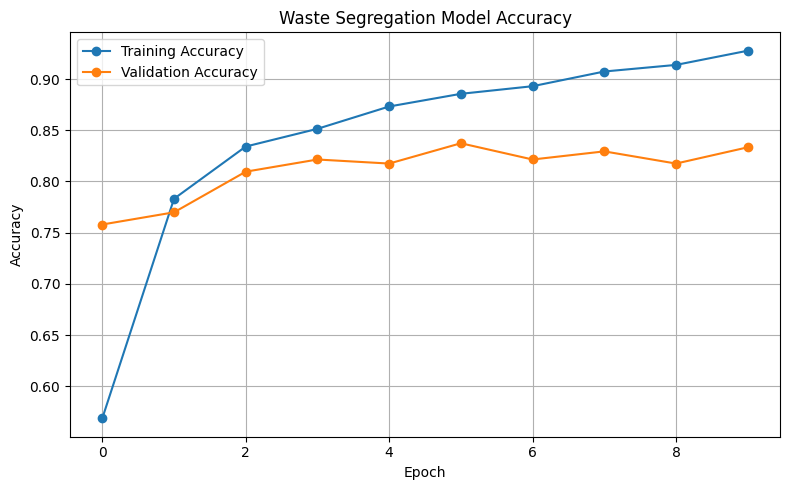

Accuracy graph saved successfully!


In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.title("Waste Segregation Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "/content/waste_accuracy_graph.png",
    dpi=300
)

plt.show()

print("Accuracy graph saved successfully!")


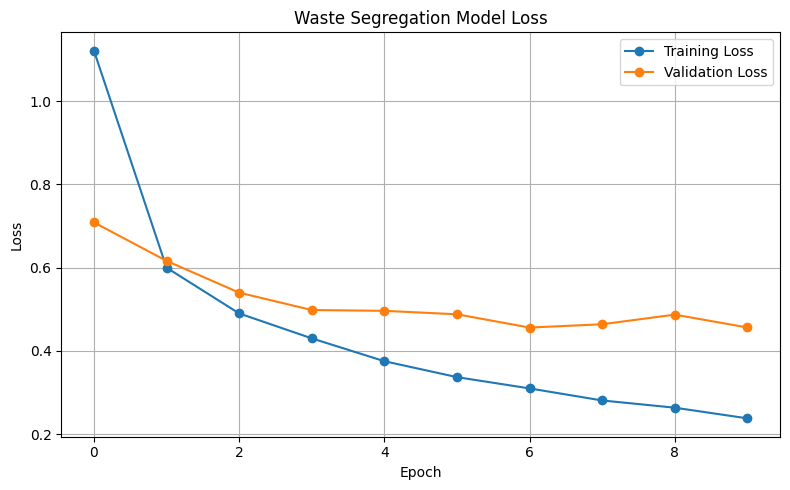

Loss graph saved successfully!


In [18]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Waste Segregation Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "/content/waste_loss_graph.png",
    dpi=300
)

plt.show()

print("Loss graph saved successfully!")


8/8 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step


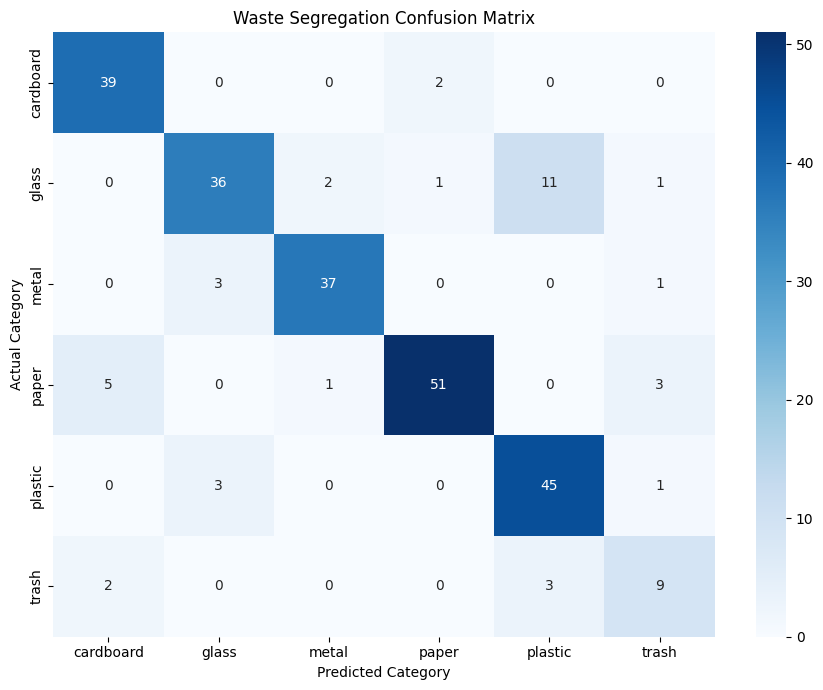


Classification Report:

              precision    recall  f1-score   support

   cardboard       0.85      0.95      0.90        41
       glass       0.86      0.71      0.77        51
       metal       0.93      0.90      0.91        41
       paper       0.94      0.85      0.89        60
     plastic       0.76      0.92      0.83        49
       trash       0.60      0.64      0.62        14

    accuracy                           0.85       256
   macro avg       0.82      0.83      0.82       256
weighted avg       0.85      0.85      0.85       256



In [19]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Get actual labels from test dataset
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predict labels for test images
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

# Create confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

# Plot confusion matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Waste Segregation Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()

plt.savefig(
    "/content/waste_confusion_matrix.png",
    dpi=300
)

plt.show()

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))
